## 5.1 Data Preprocessing

Langkah:
1. Muat dan validasi data masukan
2. Tentukan peran kolom (ID, target, numerik, kategorikal) dan cek kebocoran
3. Eksplorasi singkat sebagai dasar keputusan
4. Periksa pola nilai hilang
5. Bagi data latih dan uji **per siswa**
6. Definisikan pipeline preprocessing (dijalankan di 5.2 setelah fitur turunan ditambahkan)

### 5.1.1 Konfigurasi dan pemuatan data

In [1]:
import time
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, Imputer, ImputerModel,
                                VectorAssembler)

try:
    display
except NameError:            #di luar Jupyter
    display = print

#Parameter (samakan dengan file ETL)
HDFS   = "hdfs://namenode:9000/data/oulad"
CUTOFF = None                       #
SUFFIX = "" if CUTOFF is None else f"_d{CUTOFF}"
KEYS   = ["code_module", "code_presentation", "id_student"]

TARGET  = "final_result"
ID_COLS = ["id_student", "label_binary"]   
TRAIN_PCT = 80                             #persen siswa untuk data latih
SEED = 42

spark = (SparkSession.builder
         .appName("oulad-modeling")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())

raw = (spark.read.option("header", True).option("inferSchema", True)
       .csv(f"{HDFS}/processed/features_clean{SUFFIX}")
       .cache())

n_rows = raw.count()
print(f"{n_rows:,} baris, {len(raw.columns)} kolom")
raw.printSchema()

32,593 baris, 52 kolom
root
 |-- code_module: string (nullable = true)
 |-- code_presentation: string (nullable = true)
 |-- id_student: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- region: string (nullable = true)
 |-- highest_education: string (nullable = true)
 |-- imd_band: string (nullable = true)
 |-- age_band: string (nullable = true)
 |-- num_of_prev_attempts: integer (nullable = true)
 |-- studied_credits: integer (nullable = true)
 |-- disability: string (nullable = true)
 |-- final_result: string (nullable = true)
 |-- module_presentation_length: integer (nullable = true)
 |-- date_registration: integer (nullable = true)
 |-- total_click: integer (nullable = true)
 |-- active_days: integer (nullable = true)
 |-- distinct_sites: integer (nullable = true)
 |-- first_activity_day: integer (nullable = true)
 |-- last_activity_day: integer (nullable = true)
 |-- avg_click_per_active_day: double (nullable = true)
 |-- click_dataplus: integer (nullable = tru

### 5.1.2 Validasi data masukan
Memastikan keluaran ETL utuh: tidak ada key ganda, tidak ada ? yang lolos sebagai teks, dan kolom yang seharusnya angka tidak terbaca sebagai string.

In [2]:
n_dupe   = raw.groupBy(*KEYS).count().filter("count > 1").count()
str_cols = [c for c, t in raw.dtypes if t == "string"]
n_qmark  = sum(raw.filter(F.col(c) == "?").count() for c in str_cols)

EXPECTED_NUMERIC = ["num_of_prev_attempts", "studied_credits", "module_presentation_length",
                    "date_registration", "total_click", "active_days", "distinct_sites",
                    "n_assessments", "avg_score", "n_late", "has_vle_activity", "has_assessment"]
dtypes = dict(raw.dtypes)
wrong_type = [c for c in EXPECTED_NUMERIC if c in dtypes and dtypes[c] == "string"]

print(f"kunci ganda        : {n_dupe}")
print(f"nilai '?' tersisa  : {n_qmark}")
print(f"numerik terbaca string: {wrong_type}")

assert TARGET in raw.columns, f"kolom target {TARGET} tidak ada"
assert n_dupe == 0, "Ada kunci (modul, presentasi, siswa) ganda"
assert n_qmark == 0, "Masih ada '?' sebagai teks"
assert not wrong_type, "Ada kolom numerik terbaca sebagai string; periksa inferSchema/ETL"
print("Validasi lulus.")

kunci ganda        : 0
nilai '?' tersisa  : 0
numerik terbaca string: []
Validasi lulus.


### 5.1.3 Pencegahan Data Leakage
Kolom dipisah menjadi ID/label (tidak jadi fitur), numerik, dan kategorikal. label_binary diturunkan langsung dari final_result, sehingga wajib dikeluarkan. Pemeriksaan nama kolom di bawah menjaga agar kolom serupa tidak ikut masuk tanpa sengaja.

In [3]:
NUM_TYPES = ("int", "bigint", "smallint", "tinyint", "double", "float")

candidates = [c for c in raw.columns if c not in ID_COLS + [TARGET]]
num_cols = [c for c, t in raw.dtypes
            if c in candidates and (t in NUM_TYPES or t.startswith("decimal"))]
cat_cols = [c for c, t in raw.dtypes if c in candidates and t == "string"]

unassigned = set(candidates) - set(num_cols) - set(cat_cols)
assert not unassigned, f"Tipe kolom tidak dikenali: {unassigned}"

#Tidak boleh ada kolom turunan label atau info pengunduran diri
FORBIDDEN = ("result", "label", "unregistration")
leak = [c for c in num_cols + cat_cols if any(k in c.lower() for k in FORBIDDEN)]
assert not leak, f"Kolom berpotensi bocor: {leak}"

print(f"numerik     : {len(num_cols)} kolom")
print(f"kategorikal : {len(cat_cols)} kolom -> {cat_cols}")
print(f"dikeluarkan : {ID_COLS} (+ target {TARGET})")

print("\nKardinalitas kolom kategorikal:")
raw.agg(*[F.countDistinct(c).alias(c) for c in cat_cols]).show(truncate=False)

numerik     : 41 kolom
kategorikal : 8 kolom -> ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']
dikeluarkan : ['id_student', 'label_binary'] (+ target final_result)

Kardinalitas kolom kategorikal:
+-----------+-----------------+------+------+-----------------+--------+--------+----------+
|code_module|code_presentation|gender|region|highest_education|imd_band|age_band|disability|
+-----------+-----------------+------+------+-----------------+--------+--------+----------+
|7          |4                |2     |13    |5                |10      |3       |2         |
+-----------+-----------------+------+------+-----------------+--------+--------+----------+



### 5.1.4 Eksplorasi singkat

In [4]:
#Persebaran data fitur target
(raw.groupBy(TARGET).count()
    .withColumn("persen", F.round(F.col("count") / n_rows * 100, 2))
    .orderBy(F.desc("count")).show())

#Jumlah null per kolom (hanya yang > 0)
nulls = (raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw.columns])
            .first().asDict())
null_rows = [(c, int(v), round(v / n_rows * 100, 2)) for c, v in nulls.items() if v]
if null_rows:
    (spark.createDataFrame(null_rows, ["kolom", "jumlah_null", "persen"])
          .orderBy(F.desc("jumlah_null")).show(50, truncate=False))
else:
    print("Tidak ada null.")

+------------+-----+------+
|final_result|count|persen|
+------------+-----+------+
|        Pass|12361| 37.93|
|   Withdrawn|10156| 31.16|
|        Fail| 7052| 21.64|
| Distinction| 3024|  9.28|
+------------+-----+------+

+------------------+-----------+------+
|kolom             |jumlah_null|persen|
+------------------+-----------+------+
|avg_score_cma     |17493      |53.67 |
|avg_score_tma     |7805       |23.95 |
|avg_score         |6777       |20.79 |
|max_score         |6777       |20.79 |
|min_score         |6777       |20.79 |
|avg_days_late     |6754       |20.72 |
|first_activity_day|3365       |10.32 |
|last_activity_day |3365       |10.32 |
|imd_band          |1111       |3.41  |
|date_registration |45         |0.14  |
+------------------+-----------+------+



In [5]:
#Kemencengan (skewness) kolom numerik: nilai besar = ekor panjang / outlier
skew_cols = [c for c in num_cols if not c.startswith("has_")]   # flag biner tidak relevan
skew = raw.select([F.skewness(c).alias(c) for c in skew_cols]).first().asDict()
skew_rows = sorted(((c, round(v, 2)) for c, v in skew.items() if v is not None and v == v),
                   key=lambda x: -abs(x[1]))
print("10 kolom paling menceng:")
for c, v in skew_rows[:10]:
    print(f"  {c:28s} {v:>8.2f}")

10 kolom paling menceng:
  click_repeatactivity           114.43
  click_glossary                  47.60
  click_resource                  34.71
  click_sharedsubpage             27.91
  click_url                       13.10
  click_ouelluminate              11.70
  n_banked                        11.49
  click_page                      10.66
  click_externalquiz               9.69
  click_oucollaborate              7.83


Kolom klik (total_click, click_*) sangat menceng karena banyak outlier. Outlier tidak dibuang karena siswa yang sangat aktif adalah data yang valid. Maka dari itu, dipilih model berbasis tree yang tidak terpengaruh skala maupun ekor panjang. Karena semua model di bab ini berbasis tree, proses scaling tidak diperlukan.

### 5.1.5 Pola nilai hilang
Pastikan apakah null itu memang tidak ada aktivitas atau tugas atau benar-benar data yang hilang.

In [6]:
print("Aktivitas VLE: null pada last_activity_day vs flag has_vle_activity")
(raw.groupBy("has_vle_activity")
    .agg(F.count("*").alias("n_siswa"),
         F.sum(F.col("last_activity_day").isNull().cast("int")).alias("null_last_activity_day"))
    .orderBy("has_vle_activity").show())

print("Tugas: null pada avg_score vs flag has_assessment")
(raw.groupBy("has_assessment")
    .agg(F.count("*").alias("n_siswa"),
         F.sum(F.col("avg_score").isNull().cast("int")).alias("null_avg_score"))
    .orderBy("has_assessment").show())

Aktivitas VLE: null pada last_activity_day vs flag has_vle_activity
+----------------+-------+----------------------+
|has_vle_activity|n_siswa|null_last_activity_day|
+----------------+-------+----------------------+
|               0|   3365|                  3365|
|               1|  29228|                     0|
+----------------+-------+----------------------+

Tugas: null pada avg_score vs flag has_assessment
+--------------+-------+--------------+
|has_assessment|n_siswa|null_avg_score|
+--------------+-------+--------------+
|             0|   6754|          6754|
|             1|  25839|            23|
+--------------+-------+--------------+



Null pada kolom aktivitas dan skor hampir seluruhnya struktural: selalu bertepatan dengan flag has_vle_activity = 0 atau has_assessment = 0. Sisanya (siswa punya tugas tetapi skor null) adalah data yang benar-benar hilang di sumber.

Strategi null pengisian data
- Kolom hitungan (total_click, n_late, click_*, dst.): Sudah diisi 0 di ETL
- first/last_activity_day, kolom skor, avg_days_late: Median dari data latih (Imputer)
- date_registration: Median dari data latih
- imd_band (kategorikal): Semua kolom one-hot bernilai 0

Median dipelajari dari data latih saja agar tidak ada informasi data uji yang masuk.

### 5.1.6 Pembagian data latih dan uji
Pembagian dilakukan per id_student karena apabila seorang siswa mengambil beberapa modul, ia bisa muncul di data train dan test. Akibatnya, model mendapatkan informasi yang seharusnya ia tidak dapatkan (data leakage).

In [7]:
bucket = F.pmod(F.hash(F.col("id_student")), F.lit(100))

train = raw.filter(bucket < TRAIN_PCT).cache()
test  = raw.filter(bucket >= TRAIN_PCT).cache()

n_train, n_test = train.count(), test.count()
overlap = train.select("id_student").intersect(test.select("id_student")).count()

print(f"latih: {n_train:,} baris ({n_train / n_rows:.1%}) | uji: {n_test:,} baris ({n_test / n_rows:.1%})")
print(f"siswa yang muncul di kedua set: {overlap}")
assert n_train + n_test == n_rows, "Ada baris yang hilang saat pembagian"
assert overlap == 0, "Siswa yang sama ada di data latih dan uji"

#Proporsi kelas harus mirip di kedua set
dist = (train.groupBy(TARGET).agg((F.count("*") / n_train).alias("latih"))
        .join(test.groupBy(TARGET).agg((F.count("*") / n_test).alias("uji")), TARGET)
        .select(TARGET, F.round("latih", 3).alias("latih"), F.round("uji", 3).alias("uji")))
dist.show()

latih: 26,096 baris (80.1%) | uji: 6,497 baris (19.9%)
siswa yang muncul di kedua set: 0
+------------+-----+-----+
|final_result|latih|  uji|
+------------+-----+-----+
|        Pass|0.379|0.382|
| Distinction|0.093|0.091|
|   Withdrawn|0.311|0.313|
|        Fail|0.217|0.215|
+------------+-----+-----+



### 5.1.7 Definisi pipeline preprocessing
Tahapan: 
- indeks label
- indeks + one-hot kolom kategorikal
- imputasi median → gabung menjadi vektor features.
Pipeline dilatih hanya pada data latih lalu diterapkan ke data uji.

In [8]:
def to_model_df(df, num_cols, cat_cols):
    """Pilih kolom yang dipakai dan ubah numerik ke double (syarat Imputer)."""
    return df.select(*ID_COLS, TARGET,
                     *[F.col(c).cast("double").alias(c) for c in num_cols],
                     *cat_cols)

def build_prep(num_cols, cat_cols):
    label_idx = StringIndexer(inputCol=TARGET, outputCol="label", handleInvalid="skip")
    cat_idx = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
               for c in cat_cols]
    cat_ohe = OneHotEncoder(inputCols=[f"{c}_idx" for c in cat_cols],
                            outputCols=[f"{c}_ohe" for c in cat_cols])
    imputer = Imputer(inputCols=num_cols,
                      outputCols=[f"{c}_imp" for c in num_cols],
                      strategy="median")
    assembler = VectorAssembler(inputCols=[f"{c}_imp" for c in num_cols] +
                                          [f"{c}_ohe" for c in cat_cols],
                                outputCol="features", handleInvalid="keep")
    return Pipeline(stages=[label_idx, *cat_idx, cat_ohe, imputer, assembler])

def prepare(train_df, test_df, num_cols, cat_cols):
    """Latih pipeline pada data latih, lalu terapkan ke data latih dan uji."""
    train_m = to_model_df(train_df, num_cols, cat_cols)
    test_m  = to_model_df(test_df, num_cols, cat_cols)

    # Imputer gagal jika ada kolom yang seluruhnya null di data latih
    non_null = train_m.select([F.count(c).alias(c) for c in num_cols]).first().asDict()
    all_null = [c for c, v in non_null.items() if v == 0]
    assert not all_null, f"Kolom seluruhnya null di data latih: {all_null}"

    model = build_prep(num_cols, cat_cols).fit(train_m)       # hanya data latih
    return model, model.transform(train_m).cache(), model.transform(test_m).cache()

# 5.2 Feature Engineering

Fokus dari langkah ini adalah seleksi fitur. Tidak semua fitur berguna. Fitur yang tidak informatif menambah noise, memperlambat pelatihan, dan membuat model lebih sulit dijelaskan. Bagian ini mencari jumlah fitur sekecil mungkin yang performanya sama baiknya dengan semua fitur.

Dibagi jadi tiga langkah:
- Peringkat: Random Forest dilatih pada semua fitur, lalu tiap fitur diberi skor importance: seberapa besar fitur itu membantu pohon-pohon memisahkan kelas.
- Uji: Model dilatih hanya dengan *K* fitur teratas untuk beberapa nilai K, lalu diukur dengan validasi silang.
- Pilih: Ambil K terkecil yang skornya tidak lebih rendah dari skor terbaik dikurangi satu standard error.

In [9]:
import re
from pyspark.ml.functions import vector_to_array
from sklearn.ensemble import RandomForestClassifier as FsRF
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

FS_TREES = 100      #jumlah pohon Random Forest untuk seleksi
FS_FOLDS = 5        #jumlah lipatan validasi silang

### 5.2.1 Fitur kandidat
Semua fitur dasar hasil ETL dipakai sebagai kandidat. Satu kolom kategorikal menjadi beberapa kolom one-hot pada vektor fitur, sehingga importance dijumlahkan kembali per kolom asli. Dengan begitu, yang diseleksi adalah variabel seperti region, bukan potongan one-hot seperti region_Scotland.

In [10]:
def get_feature_names(d):
    """Nama fitur sesuai urutan indeks di vektor `features`."""
    attrs = d.schema["features"].metadata["ml_attr"]["attrs"]
    return [re.sub(r"_imp$", "", a["name"])
            for a in sorted((a for grp in attrs.values() for a in grp), key=lambda a: a["idx"])]

def collect_xy(d):
    pdf = d.select("id_student", "label", vector_to_array("features").alias("f")).toPandas()
    return (np.vstack(pdf["f"].to_numpy()), pdf["label"].to_numpy().astype(int),
            pdf["id_student"].to_numpy())

#Semua fitur dasar, dengan pipeline preprocessing yang sama (5.1.7)
prep_all, train_p_all, test_p_all = prepare(train, test, num_cols, cat_cols)

names_all = get_feature_names(train_p_all)
n_feat_all = len(names_all)
fs_X, fs_y, fs_g = collect_xy(train_p_all)

#Kolom asli di balik tiap kolom pada vektor (region_ohe_Scotland -> region)
source_col = lambda fname: fname.split("_ohe_")[0] if "_ohe_" in fname else fname
src = np.array([str(source_col(n)) for n in names_all])
cols_all = sorted({str(c) for c in src})
assert set(cols_all) == set(num_cols) | set(cat_cols), "Kolom vektor tidak cocok dengan daftar kolom"

print(f"{len(cols_all)} kolom asli ({len(num_cols)} numerik, {len(cat_cols)} kategorikal) "
      f"-> {n_feat_all} fitur pada vektor | matriks latih: {fs_X.shape}")

49 kolom asli (41 numerik, 8 kategorikal) -> 87 fitur pada vektor | matriks latih: (26096, 87)


### 5.2.2 Langkah 1: peringkat kepentingan fitur
Random Forest dilatih pada seluruh data latih. Importance tiap kolom asli adalah jumlah importance semua kolom vektor miliknya, sehingga totalnya 1. 

,importance,jenis,peringkat,kumulatif
last_activity_day,0.1801,numerik,1,0.1801
n_assessments,0.1491,numerik,2,0.3292
active_days,0.0750,numerik,3,0.4042
click_homepage,0.0569,numerik,4,0.4610
avg_score,0.0547,numerik,5,0.5158
has_assessment,0.0523,numerik,6,0.5681
avg_score_tma,0.0484,numerik,7,0.6165
max_score,0.0416,numerik,8,0.6581
click_resource,0.0364,numerik,9,0.6945
total_click,0.0346,numerik,10,0.7291


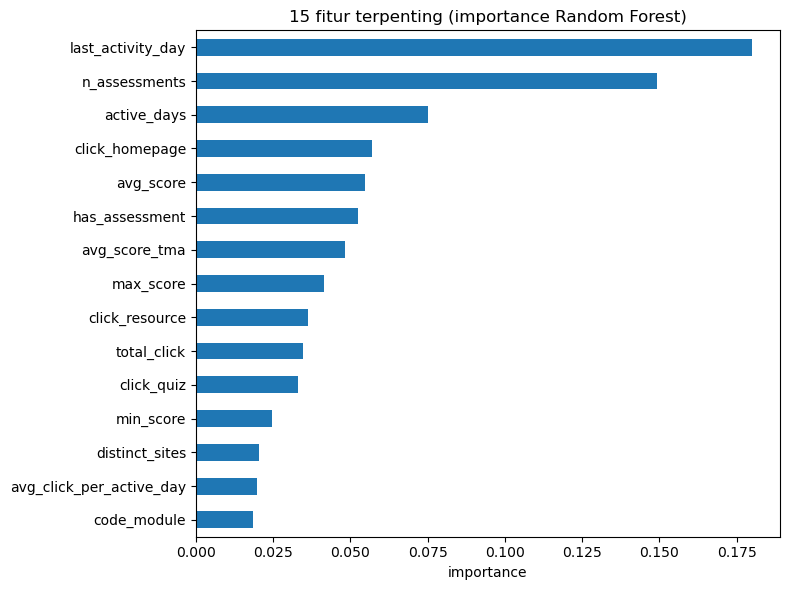

In [11]:
def rank_columns(X, y, rows):
    """Peringkat kolom asli menurut importance Random Forest yang dilatih pada baris `rows`."""
    m = FsRF(n_estimators=FS_TREES, max_depth=8, n_jobs=-1, random_state=SEED).fit(X[rows], y[rows])
    imp = pd.Series(m.feature_importances_).groupby(src).sum()
    return imp.sort_values(ascending=False)

rank_full = rank_columns(fs_X, fs_y, np.arange(len(fs_y)))

rank_tbl = pd.DataFrame({"importance": rank_full})
rank_tbl["jenis"] = ["kategorikal" if c in cat_cols else "numerik" for c in rank_tbl.index]
rank_tbl["peringkat"] = np.arange(1, len(rank_tbl) + 1)
rank_tbl["kumulatif"] = rank_tbl["importance"].cumsum()
display(rank_tbl.head(20).round(4))

fig, ax = plt.subplots(figsize=(8, 6))
rank_tbl["importance"].head(15)[::-1].plot.barh(ax=ax)
ax.set_title("15 fitur terpenting (importance Random Forest)")
ax.set_xlabel("importance")
plt.tight_layout(); plt.show()

### 5.2.3 Langkah 2 dan 3: berapa fitur yang dibutuhkan?
Untuk tiap jumlah kolom K, model dilatih hanya dengan K kolom teratas, lalu diukur dengan macro F1 pada validasi silang 5 lipatan. Lipatan berstrata menurut kelas dan dikelompokkan per id_student (siswa yang sama tidak berada di lipatan latih dan validasi sekaligus).

Peringkat dihitung ulang di dalam setiap lipatan, hanya dari bagian latih lipatan itu. Jika peringkat dihitung dari seluruh data latih.

Aturan pemilihan: pilih K terkecil dengan skor ≥ (skor terbaik − standard error skor terbaik). Penurunan sekecil itu tidak dapat dibedakan dari fluktuasi antar lipatan, sehingga model yang lebih sederhana dipilih.

waktu: 51 s


,macro_f1_mean,macro_f1_std,se
jumlah_kolom,,,
3,0.4935,0.0060,0.0027
5,0.5966,0.0605,0.0271
8,0.6202,0.0128,0.0057
10,0.6257,0.0137,0.0061
15,0.6278,0.0138,0.0062
20,0.6317,0.0120,0.0054
25,0.6271,0.0142,0.0063
30,0.6255,0.0142,0.0063
40,0.6124,0.0106,0.0047


skor terbaik: K = 20 (macro F1 0.6317)
ambang satu galat baku: 0.6263  ->  K terpilih = 15 dari 49 kolom


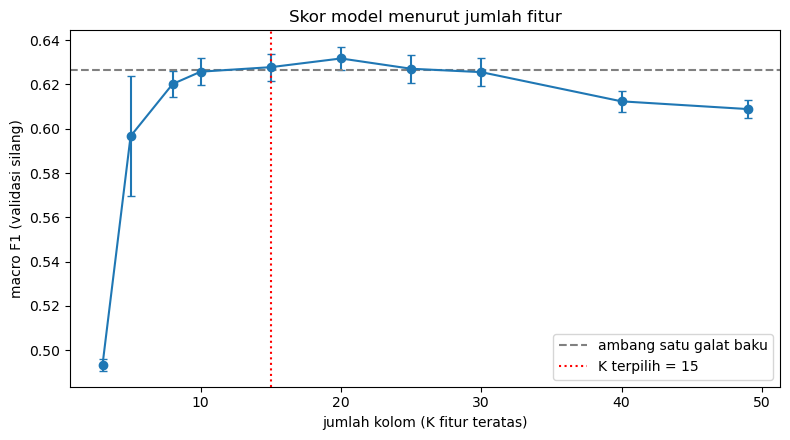

In [12]:
folds   = list(StratifiedGroupKFold(n_splits=FS_FOLDS, shuffle=True, random_state=SEED)
               .split(fs_X, fs_y, fs_g))
all_idx = np.arange(fs_X.shape[1])
n_cols  = len(cols_all)
K_LIST  = sorted({k for k in [3, 5, 8, 10, 15, 20, 25, 30, 40, n_cols] if k <= n_cols})

def fit_score(tr, va, idx):
    m = FsRF(n_estimators=FS_TREES, max_depth=8, n_jobs=-1, random_state=SEED)
    m.fit(fs_X[np.ix_(tr, idx)], fs_y[tr])
    return f1_score(fs_y[va], m.predict(fs_X[np.ix_(va, idx)]), average="macro")

t0 = time.perf_counter()
curve = {k: [] for k in K_LIST}
for tr, va in folds:
    rank = rank_columns(fs_X, fs_y, tr)                 #peringkat dihitung ulang di tiap lipatan
    for k in K_LIST:
        idx = np.flatnonzero(np.isin(src, rank.index[:k]))
        curve[k].append(fit_score(tr, va, idx))
print(f"waktu: {time.perf_counter() - t0:.0f} s")

curve_df = pd.DataFrame({"macro_f1_mean": [np.mean(curve[k]) for k in K_LIST],
                         "macro_f1_std":  [np.std(curve[k], ddof=1) for k in K_LIST]},
                        index=pd.Index(K_LIST, name="jumlah_kolom"))
curve_df["se"] = curve_df["macro_f1_std"] / np.sqrt(FS_FOLDS)

best_k    = curve_df["macro_f1_mean"].idxmax()
threshold = curve_df.loc[best_k, "macro_f1_mean"] - curve_df.loc[best_k, "se"]
K_BEST    = int(curve_df.index[curve_df["macro_f1_mean"] >= threshold].min())

display(curve_df.round(4))
print(f"skor terbaik: K = {best_k} (macro F1 {curve_df.loc[best_k, 'macro_f1_mean']:.4f})")
print(f"ambang satu standard error: {threshold:.4f}  ->  K terpilih = {K_BEST} dari {n_cols} kolom")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(curve_df.index, curve_df["macro_f1_mean"], yerr=curve_df["se"], marker="o", capsize=3)
ax.axhline(threshold, color="gray", linestyle="--", label="ambang satu standard error")
ax.axvline(K_BEST, color="red", linestyle=":", label=f"K terpilih = {K_BEST}")
ax.set_xlabel("jumlah kolom (K fitur teratas)"); ax.set_ylabel("macro F1 (validasi silang)")
ax.set_title("Skor model menurut jumlah fitur"); ax.legend()
plt.tight_layout(); plt.show()

### 5.2.5 Set fitur final
Kolom yang dipertahankan adalah 15 teratas dari peringkat pada seluruh data latih (langkah 1). Pipeline preprocessing dijalankan ulang hanya dengan kolom tersebut.

In [13]:
final_cols = [str(c) for c in rank_full.index[:K_BEST]]
if not any(c in cat_cols for c in final_cols):          #pipeline 5.1.7 membutuhkan >= 1 kolom kategorikal
    extra = str(next(c for c in rank_full.index if c in cat_cols))
    final_cols.append(extra)
    print(f"Catatan: tidak ada kolom kategorikal terpilih; '{extra}' ditambahkan agar pipeline berjalan")

final_num = [c for c in num_cols if c in final_cols]
final_cat = [c for c in cat_cols if c in final_cols]
removed   = [c for c in cols_all if c not in final_cols]

prep_model, train_p, test_p = prepare(train, test, final_num, final_cat)
labels = prep_model.stages[0].labels
feature_names = get_feature_names(train_p)
n_feat = len(feature_names)

#Tidak ada null tersisa setelah imputasi (latih dan uji)
imp_cols_final = [f"{c}_imp" for c in final_num]
for name, d_ in [("latih", train_p), ("uji", test_p)]:
    left = d_.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in imp_cols_final]).first().asDict()
    n_left = sum(v for v in left.values() if v)
    print(f"null tersisa setelah imputasi ({name}): {n_left}")
    assert n_left == 0

print(f"\nPemetaan label: {dict(enumerate(labels))}")
print(f"kolom dipertahankan ({len(final_cols)}): {final_cols}")
print(f"kolom dihapus ({len(removed)}): {removed}")
print(f"jumlah fitur pada vektor: semua {n_feat_all} -> terpilih {n_feat}")

null tersisa setelah imputasi (latih): 0
null tersisa setelah imputasi (uji): 0

Pemetaan label: {0: 'Pass', 1: 'Withdrawn', 2: 'Fail', 3: 'Distinction'}
kolom dipertahankan (15): ['last_activity_day', 'n_assessments', 'active_days', 'click_homepage', 'avg_score', 'has_assessment', 'avg_score_tma', 'max_score', 'click_resource', 'total_click', 'click_quiz', 'min_score', 'distinct_sites', 'avg_click_per_active_day', 'code_module']
kolom dihapus (34): ['age_band', 'avg_days_late', 'avg_score_cma', 'click_dataplus', 'click_dualpane', 'click_externalquiz', 'click_folder', 'click_forumng', 'click_glossary', 'click_htmlactivity', 'click_oucollaborate', 'click_oucontent', 'click_ouelluminate', 'click_ouwiki', 'click_page', 'click_questionnaire', 'click_repeatactivity', 'click_sharedsubpage', 'click_subpage', 'click_url', 'code_presentation', 'date_registration', 'disability', 'first_activity_day', 'gender', 'has_vle_activity', 'highest_education', 'imd_band', 'module_presentation_length', 'n_

## 5.3 Algoritma Machine Learning

Penjelasan teori model Machine Learning dapat dilihat pada laporan di file PDF.

## 5.4 Proses Pengembangan Model dengan dan tanpa Spark MLlib

Tiga model dilatih dengan dua cara berbeda pada data dan fitur yang sama. Maka dari itu, perbedaan hasil dan waktu murni berasal dari mesin pelatihannya.


- Decision Tree: Spark MLlib DecisionTreeClassifier dan scikit-learn DecisionTreeClassifier
- Random Forest: Spark MLlib RandomForestClassifier dan scikit-learn RandomForestClassifier
- XGBoost: xgboost.spark.SparkXGBClassifier dan xgboost.XGBClassifier

Spark MLlib tidak punya XGBoost bawaan, jadi versi Spark memakai pembungkus resmi dari paket xgboost.

### 5.4.1 Konfigurasi

In [14]:
try:
    import sklearn, xgboost
except ImportError as e:
    raise ImportError("Pasang dulu: pip install scikit-learn xgboost matplotlib  (lalu restart kernel)") from e

try:
    from xgboost.spark import SparkXGBClassifier
    HAS_SPARK_XGB = True
except ImportError:
    HAS_SPARK_XGB = False
    print("xgboost.spark tidak tersedia: XGBoost versi Spark dilewati")

from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.functions import vector_to_array, array_to_vector

#Hyperparameter yang sama
HP = {
    "dt":  {"max_depth": 8},
    "rf":  {"n_estimators": 200, "max_depth": 8},
    "xgb": {"n_estimators": 200, "max_depth": 6, "learning_rate": 0.1},
}
N_RUNS = 3                                                   #pengulangan untuk median waktu
NUM_WORKERS = max(1, min(4, spark.sparkContext.defaultParallelism))   #pekerja XGBoost-Spark

for model_name, params in HP.items():
    print(f"{model_name:4s}", params)
print(f"\nversi: sklearn {sklearn.__version__} | xgboost {xgboost.__version__} | spark {spark.version}")
print(f"N_RUNS = {N_RUNS} | NUM_WORKERS (XGBoost-Spark) = {NUM_WORKERS}")

dt   {'max_depth': 8}
rf   {'n_estimators': 200, 'max_depth': 8}
xgb  {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}

versi: sklearn 1.5.1 | xgboost 2.1.4 | spark 3.5.1
N_RUNS = 3 | NUM_WORKERS (XGBoost-Spark) = 4


### 5.4.2 Pelatihan dengan Spark
Waktu fit diukur dari .fit(). Waktu prediksi diukur dengan memaksa Spark menghitung seluruh kolom prediction pada data uji.. Angka yang dilaporkan adalah median dari 3 pengulangan. Pengulangan pertama di Spark biasanya lebih lambat karena pemanasan JVM.

In [15]:
results = {}        
spark_models = {}

def timed(fn, n=N_RUNS):
    times, out = [], None
    for _ in range(n):
        t0 = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - t0)
    return out, float(np.median(times))

def run_spark(family, engine, est, tr, te):
    model, t_fit = timed(lambda: est.fit(tr))
    _, t_pred = timed(lambda: model.transform(te).select("prediction")
                                   .write.format("noop").mode("overwrite").save())
    pdf = model.transform(te).select("label", "prediction").toPandas()
    key = f"{family} - {engine}"
    results[key] = dict(family=family, engine=engine,
                        y_true=pdf["label"].to_numpy().astype(int),
                        y_pred=pdf["prediction"].to_numpy().astype(int),
                        fit_s=t_fit, pred_s=t_pred)
    spark_models[key] = model
    print(f"{key:36s} fit {t_fit:7.2f} s | prediksi {t_pred:6.2f} s")

run_spark("Decision Tree", "Spark MLlib",
          DecisionTreeClassifier(featuresCol="features", labelCol="label",
                                 maxDepth=HP["dt"]["max_depth"], seed=SEED),
          train_p, test_p)

run_spark("Random Forest", "Spark MLlib",
          RandomForestClassifier(featuresCol="features", labelCol="label",
                                 numTrees=HP["rf"]["n_estimators"],
                                 maxDepth=HP["rf"]["max_depth"], seed=SEED),
          train_p, test_p)

if HAS_SPARK_XGB:
    try:
        to_dense = lambda d: (d.select("label", array_to_vector(vector_to_array("features")).alias("features_dense"))
                               .cache())
        train_xd, test_xd = to_dense(train_p), to_dense(test_p)
        train_xd.count(); test_xd.count()

        run_spark("XGBoost", "Spark (xgboost.spark)",
                  SparkXGBClassifier(features_col="features_dense", label_col="label",
                                     num_workers=NUM_WORKERS, tree_method="hist",
                                     n_estimators=HP["xgb"]["n_estimators"],
                                     max_depth=HP["xgb"]["max_depth"],
                                     learning_rate=HP["xgb"]["learning_rate"],
                                     random_state=SEED),
                  train_xd, test_xd)
    except Exception as e:
        print(f"XGBoost versi Spark GAGAL dan dilewati: {type(e).__name__}: {str(e)[:200]}")
        print("Penyebab yang umum: versi xgboost tidak cocok dengan versi pyspark "
              f"(sekarang xgboost {xgboost.__version__}, pyspark {spark.version}). "
              "Pasang versi xgboost yang sesuai, lalu restart kernel.")

Decision Tree - Spark MLlib          fit    2.04 s | prediksi   0.20 s
Random Forest - Spark MLlib          fit   49.08 s | prediksi   1.48 s


2026-11-01 09:38:17,194 INFO XGBoost-PySpark: _fit Running xgboost-2.1.4 on 4 workers with
	booster params: {'objective': 'multi:softprob', 'device': 'cpu', 'learning_rate': 0.1, 'max_depth': 6, 'random_state': 42, 'tree_method': 'hist', 'num_class': 4, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 200}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}
2026-11-01 09:38:39,868 INFO XGBoost-PySpark: _fit Finished xgboost training!
2026-11-01 09:38:40,620 INFO XGBoost-PySpark: _fit Running xgboost-2.1.4 on 4 workers with
	booster params: {'objective': 'multi:softprob', 'device': 'cpu', 'learning_rate': 0.1, 'max_depth': 6, 'random_state': 42, 'tree_method': 'hist', 'num_class': 4, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 200}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}
2026-11-01 09:38:58,305 INFO XGBoost-PySpark: _fit Finished xgboost training!
2026-11-01 09:38:58,783 INFO XGBoost-PySpark: _fit Running xgboo

XGBoost - Spark (xgboost.spark)      fit   18.37 s | prediksi   0.56 s


### 5.4.3 Pelatihan tanpa Spark
Data latih dan uji dipindahkan ke pandas/numpy (matriks fitur yang sama persis dengan yang dipakai Spark). Waktu pemindahan dicatat terpisah karena itu adalah biaya keluar dari Spark.

In [16]:
def to_pandas_xy(d):
    pdf = d.select("id_student", "label", vector_to_array("features").alias("f")).toPandas()
    return (np.vstack(pdf["f"].to_numpy()), pdf["label"].to_numpy().astype(int),
            pdf["id_student"].to_numpy())

t0 = time.perf_counter()
X_train, y_train, g_train = to_pandas_xy(train_p)
X_test,  y_test,  g_test  = to_pandas_xy(test_p)
t_collect = time.perf_counter() - t0
print(f"X_train {X_train.shape} | X_test {X_test.shape} | pemindahan data Spark -> numpy: {t_collect:.2f} s")

X_train (26096, 21) | X_test (6497, 21) | pemindahan data Spark -> numpy: 0.87 s


In [17]:
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.ensemble import RandomForestClassifier as SkRF
from xgboost import XGBClassifier

def make_sklearn_models():
    return {
        ("Decision Tree", "scikit-learn"): lambda: SkDT(max_depth=HP["dt"]["max_depth"],
                                                        random_state=SEED),
        ("Random Forest", "scikit-learn"): lambda: SkRF(n_estimators=HP["rf"]["n_estimators"],
                                                        max_depth=HP["rf"]["max_depth"],
                                                        n_jobs=-1, random_state=SEED),
        ("XGBoost", "xgboost"): lambda: XGBClassifier(n_estimators=HP["xgb"]["n_estimators"],
                                                      max_depth=HP["xgb"]["max_depth"],
                                                      learning_rate=HP["xgb"]["learning_rate"],
                                                      tree_method="hist", n_jobs=-1,
                                                      random_state=SEED),
    }

sk_models = {}
for (family, engine), make in make_sklearn_models().items():
    model, t_fit = timed(lambda: make().fit(X_train, y_train))
    y_pred, t_pred = timed(lambda: model.predict(X_test))
    key = f"{family} - {engine}"
    results[key] = dict(family=family, engine=engine, y_true=y_test, y_pred=np.asarray(y_pred).astype(int),
                        fit_s=t_fit, pred_s=t_pred)
    sk_models[key] = model
    print(f"{key:36s} fit {t_fit:7.2f} s | prediksi {t_pred:6.2f} s")

Decision Tree - scikit-learn         fit    0.21 s | prediksi   0.00 s
Random Forest - scikit-learn         fit    2.17 s | prediksi   0.15 s
XGBoost - xgboost                    fit    2.84 s | prediksi   0.05 s


## 5.5 Evaluasi Model

Semua model, baik Spark maupun non-Spark, dievaluasi dengan kode yang sama pada data uji yang sama. Dataset tidak seimbang dengan kelas Distinction paling sedikit, sehingga macro F1 dilaporkan di samping accuracy.

### 5.5.1 Ringkasan metrik dan baseline

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             precision_recall_fscore_support, confusion_matrix)

#Baseline: batas bawah yang harus dilampaui model, hanya menebak kelas mayoritas dan menebak acak sesuai proporsi.
for strat, name in [("most_frequent", "Baseline: kelas mayoritas"),
                    ("stratified",    "Baseline: acak sesuai proporsi")]:
    d = DummyClassifier(strategy=strat, random_state=SEED).fit(X_train, y_train)
    results[name] = dict(family="Baseline", engine="-", y_true=y_test, y_pred=d.predict(X_test),
                         fit_s=np.nan, pred_s=np.nan)

def summarize(r):
    yt, yp = r["y_true"], r["y_pred"]
    return {"accuracy":     accuracy_score(yt, yp),
            "macro_prec":   precision_score(yt, yp, average="macro", zero_division=0),
            "macro_recall": recall_score(yt, yp, average="macro", zero_division=0),
            "macro_f1":     f1_score(yt, yp, average="macro", zero_division=0),
            "weighted_f1":  f1_score(yt, yp, average="weighted", zero_division=0),
            "fit_s":        r["fit_s"], "pred_s": r["pred_s"]}

summary_df = (pd.DataFrame({k: summarize(r) for k, r in results.items()}).T
              .sort_values("macro_f1", ascending=False))
display(summary_df.round(4))

,accuracy,macro_prec,macro_recall,macro_f1,weighted_f1,fit_s,pred_s
XGBoost - Spark (xgboost.spark),0.7439,0.7055,0.6629,0.6743,0.7290,18.3715,0.5553
XGBoost - xgboost,0.7445,0.7079,0.6620,0.6742,0.7291,2.8436,0.0492
Decision Tree - scikit-learn,0.7257,0.6791,0.6452,0.6527,0.7087,0.2053,0.0009
Decision Tree - Spark MLlib,0.7288,0.6897,0.6317,0.6431,0.7066,2.0381,0.2022
Random Forest - Spark MLlib,0.7376,0.7131,0.6259,0.6356,0.7057,49.0845,1.4820
Random Forest - scikit-learn,0.7379,0.7141,0.6252,0.6350,0.7057,2.1740,0.1539
Baseline: acak sesuai proporsi,0.2949,0.2492,0.2492,0.2491,0.2961,NaN,NaN
Baseline: kelas mayoritas,0.3816,0.0954,0.2500,0.1381,0.2108,NaN,NaN


### 5.5.2 Kinerja per kelas

In [19]:
K = len(labels)
rows = {}
for name, r in results.items():
    p, rc, f, sup = precision_recall_fscore_support(r["y_true"], r["y_pred"],
                                                    labels=list(range(K)), zero_division=0)
    rows[name] = {**{("precision", labels[i]): p[i] for i in range(K)},
                  **{("recall",    labels[i]): rc[i] for i in range(K)},
                  **{("f1",        labels[i]): f[i] for i in range(K)}}
per_class = pd.DataFrame(rows).T
per_class.columns = pd.MultiIndex.from_tuples(per_class.columns)
display(per_class.round(3))

support = pd.Series(np.bincount(y_test, minlength=K), index=labels, name="jumlah data uji")
print("\nJumlah data uji per kelas:")
display(support.to_frame().T)

precision                              recall  \
                                     Pass Withdrawn   Fail Distinction   Pass   
Decision Tree - Spark MLlib         0.761     0.749  0.583       0.665  0.928   
Random Forest - Spark MLlib         0.757     0.742  0.638       0.715  0.948   
XGBoost - Spark (xgboost.spark)     0.787     0.764  0.603       0.669  0.905   
Decision Tree - scikit-learn        0.773     0.751  0.559       0.633  0.896   
Random Forest - scikit-learn        0.757     0.743  0.637       0.720  0.948   
XGBoost - xgboost                   0.786     0.762  0.606       0.678  0.912   
Baseline: kelas mayoritas           0.382     0.000  0.000       0.000  1.000   
Baseline: acak sesuai proporsi      0.375     0.321  0.215       0.086  0.363   

                                                                 f1            \
                                Withdrawn   Fail Distinction   Pass Withdrawn   
Decision Tree - Spark MLlib         0.839  0.348       0.411  0.836     0.792   
Random Forest - Spark MLlib         0.891  0.298       0.367  0.842     0.810   
XGBoost - Spark (xgboost.spark)     0.851  0.411       0.484  0.842     0.805   
Decision Tree - scikit-learn        0.838  0.363       0.484  0.830     0.792   
Random Forest - scikit-learn        0.894  0.298       0.362  0.842     0.811   
XGBoost - xgboost                   0.847  0.410       0.479  0.845     0.802   
Baseline: kelas mayoritas           0.000  0.000       0.000  0.552     0.000   
Baseline: acak sesuai proporsi      0.319  0.227       0.088  0.369     0.320   

                                                    
                                  Fail Distinction  
Decision Tree - Spark MLlib      0.436       0.508  
Random Forest - Spark MLlib      0.406       0.485  
XGBoost - Spark (xgboost.spark)  0.489       0.562  
Decision Tree - scikit-learn     0.441       0.549  
Random Forest - scikit-learn     0.406       0.481  
XGBoost - xgboost                0.489       0.561  
Baseline: kelas mayoritas        0.000       0.000  
Baseline: acak sesuai proporsi   0.221       0.087


Jumlah data uji per kelas:


,Pass,Withdrawn,Fail,Distinction
jumlah data uji,2479,2031,1398,589


### 5.5.3 Confusion matrix

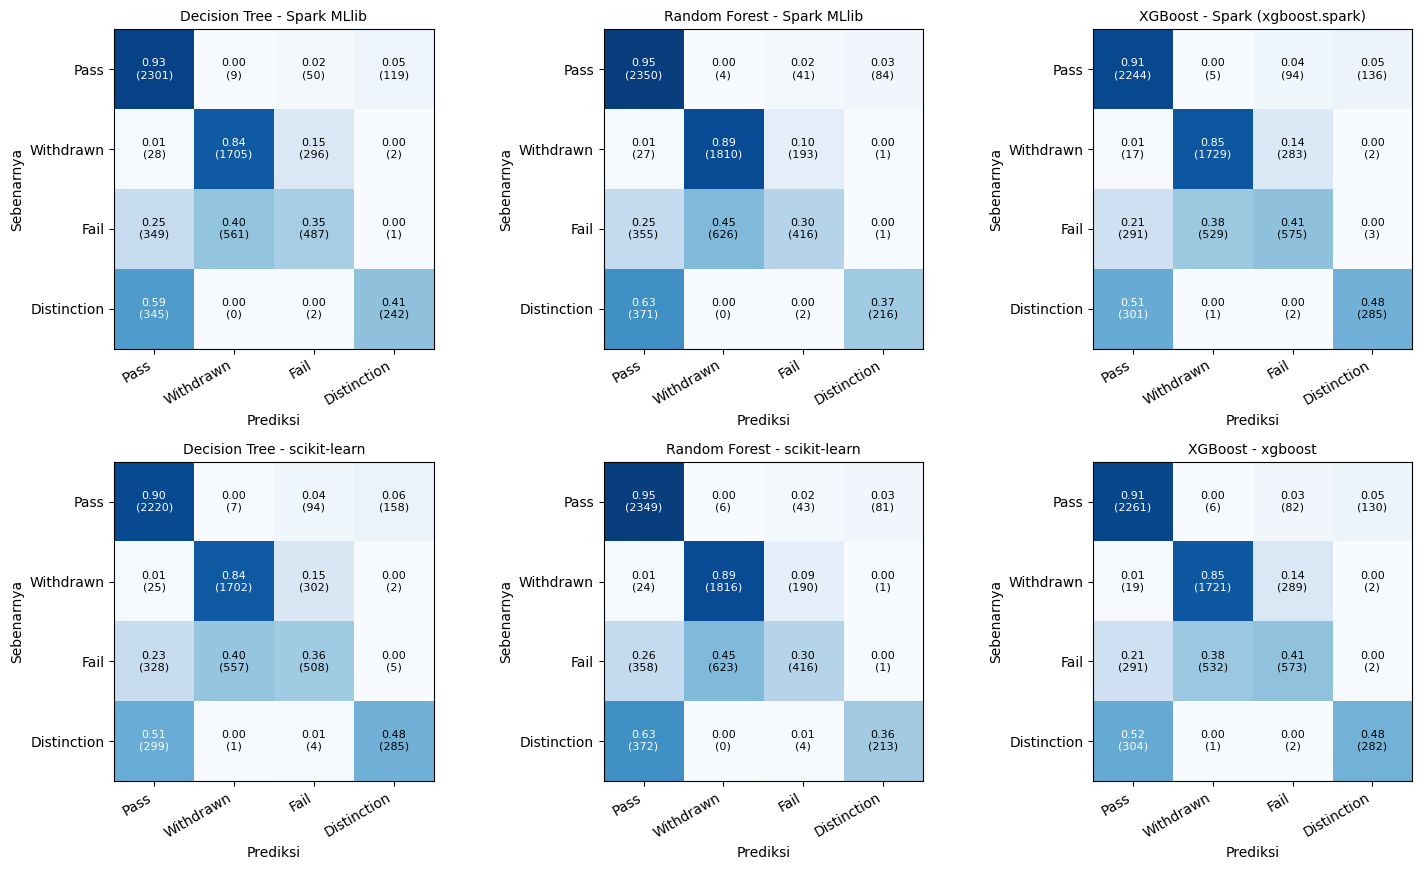

In [20]:
import matplotlib.pyplot as plt

trained = [k for k, r in results.items() if r["family"] != "Baseline"]
ncols = 3
nrows = int(np.ceil(len(trained) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.4 * nrows), squeeze=False)

for ax, name in zip(axes.ravel(), trained):
    r = results[name]
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=list(range(K)))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)                 # proporsi per baris (kelas sebenarnya)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(K)); ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(labels)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
    ax.set_title(name, fontsize=10)

for ax in axes.ravel()[len(trained):]:
    ax.axis("off")
plt.tight_layout()
plt.show()